In [1]:
import numpy as np

X = 2* np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

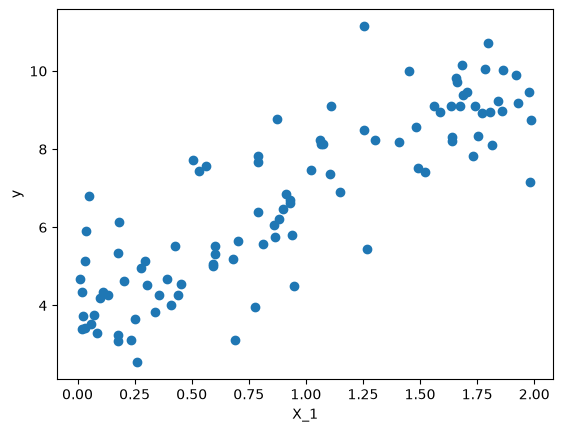

In [2]:
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.xlabel("X_1")
plt.ylabel("y")
plt.show()

In [3]:
?np.linalg.inv

Signature:       np.linalg.inv(a)
Call signature:  np.linalg.inv(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function inv at 0x7f9bc44dbab0>
File:            ~/anaconda3/lib/python3.14/site-packages/numpy/linalg/_linalg.py
Docstring:      
Compute the inverse of a matrix.

Given a square matrix `a`, return the matrix `ainv` satisfying
``a @ ainv = ainv @ a = eye(a.shape[0])``.

Parameters
----------
a : (..., M, M) array_like
    Matrix to be inverted.

Returns
-------
ainv : (..., M, M) ndarray or matrix
    Inverse of the matrix `a`.

Raises
------
LinAlgError
    If `a` is not square or inversion fails.

See Also
--------
scipy.linalg.inv : Similar function in SciPy.
numpy.linalg.cond : Compute the condition number of a matrix.
numpy.linalg.svd : Compute the singular value decomposition of a matrix.

Notes
-----
Broadcasting rules apply, see the `numpy.linalg` documentation for
details.

If `a` is detected to be singular, a `LinAlgError` is raised. I

In [4]:
X_b = np.c_[np.ones((100, 1)),  X]

In [5]:
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)

In [6]:
theta_best

array([[3.90979723],
       [2.97630881]])

In [7]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b.dot(theta_best)
y_predict

array([[3.90979723],
       [9.86241484]])

In [8]:
X_new_b

array([[1., 0.],
       [1., 2.]])

In [9]:
theta = np.linalg.inv(X_b.T.dot(X_b)) @ X_b.T @ y

In [10]:
theta

array([[3.90979723],
       [2.97630881]])

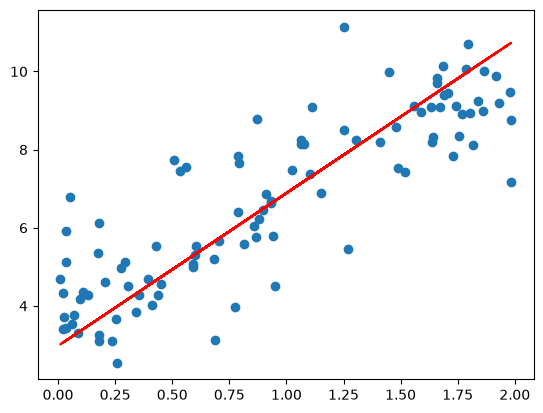

In [11]:
plt.scatter(X,y)
plt.plot(X, theta[0]*X + theta[1], 'r--')
plt.show()

## Gradient Descent

In [12]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_

(array([3.90979723]), array([[2.97630881]]))

In [13]:
distance = np.power(theta_best[0] * X + theta_best[1] - y, 2)

In [14]:
1/len(X) * np.sum(distance)

np.float64(1.6618787652151181)

In [15]:
eta = 0.5 # learning rate
n_iterations = 1000
m = 100
theta = np.random.randn(2, 1) 

theta_timeline = []
theta_timeline.append(theta)

for iteration in range(n_iterations): 
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    theta = theta - eta * gradients
    theta_timeline.append(theta)

In [16]:
theta

array([[-3.67256324e+31],
       [-4.24488274e+31]])

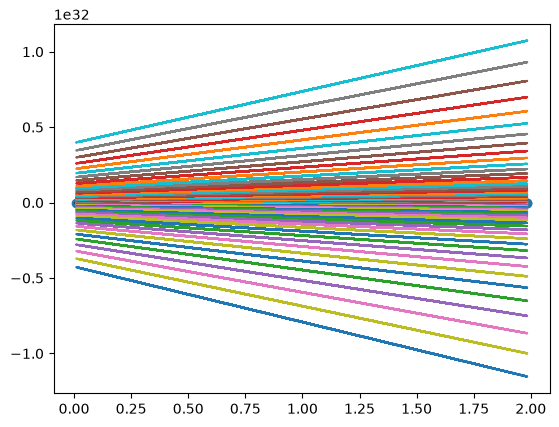

In [17]:
plt.scatter(X, y)
for t in theta_timeline: 
    plt.plot(X, t[0]* X + t[1], linestyle = "-")

plt.show()

# Stocastic Gradient Descent
- just pick random instance to compute the cost

In [18]:
n_epoches = 50
t0, t1 = 5, 50
def learning_schedule(t):
    return t0 / (t + t1)

theta = np.random.randn(2, 1) # ramdom plot

for epoch in range(n_epoches):
    for i in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = 2/m * xi.T.dot(xi.dot(theta) - yi)
        eta = learning_schedule(epoch * m + i)
        theta = theta - eta * gradients

In [19]:
theta

array([[2.6774772 ],
       [1.91984193]])

In [20]:
from sklearn.linear_model import SGDRegressor
sdg_reg = SGDRegressor(max_iter =  50, penalty = None, eta0 = 0.1)
sdg_reg.fit(X, y.ravel())

,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",None
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",50
,"eta0 eta0: float, default=0.01The initial learning rate for the 'constant', 'invscaling' or'adaptive' schedules. The default value is 0.01.Values must be in the range `(0.0, inf)`.For PA-1 (`learning_rate=pa1`) and PA-II (`pa2`), it specifies theaggressiveness parameter for the passive-aggressive algorithm, see [1] where itis called C:- For PA-I it is the maximum step size.- For PA-II it regularizes the step size (the smaller `eta0` the more it regularizes).As a general rule-of-thumb for PA, `eta0` should be small when the data isnoisy.",0.1
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1


In [21]:
(sdg_reg.intercept_, sdg_reg.coef_)

(array([3.92695348]), array([2.963707]))

# Poliminal Regression
- Use when your data is too complex

## Quandratic Example


In [22]:
m = 100
# Đổi (1, m) thành (m, 1) để tạo mảng cột dọc (100 hàng, 1 cột)
X = 6 * np.random.rand(m, 1) - 3

# Thêm (m, 1) vào np.random.randn để kích thước nhiễu khớp hoàn toàn với X
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)

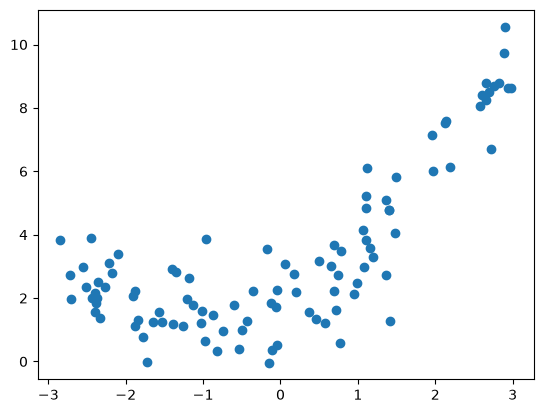

In [23]:
import matplotlib.pyplot as plt
plt.scatter(X, y)
plt.show()

In [24]:
print(X.shape, y.shape)

(100, 1) (100, 1)


In [25]:
from sklearn.preprocessing import PolynomialFeatures
poly_feature = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_feature.fit_transform(X)
X[0]

array([-1.17729376])

In [26]:
X_poly[0]

array([-1.17729376,  1.38602059])

In [27]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
lin_reg.intercept_, lin_reg.coef_

(array([1.82343531]), array([[1.02472002, 0.53277696]]))

In [28]:
lin_reg.intercept_, lin_reg.coef_

(array([1.82343531]), array([[1.02472002, 0.53277696]]))

In [35]:
X_range = np.linspace(-3,3, 100)
X_range.shape

(100,)

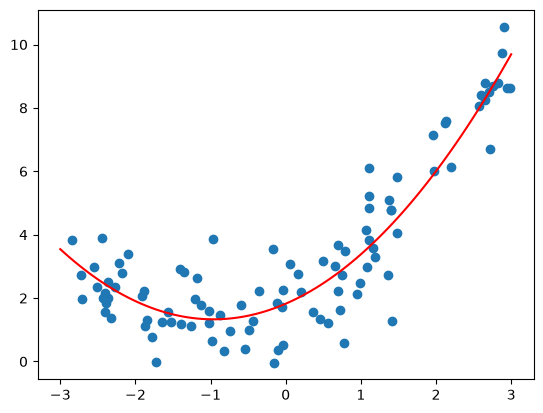

In [38]:
quadratic_y = lin_reg.coef_[0, 1] * X_range ** 2 + lin_reg.coef_[0, 0] * X_range + lin_reg.intercept_[0]
plt.scatter(X, y)
plt.plot(X_range, quadratic_y, color = "r")
plt.show()

In [43]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

def plot_learning_curves(model, X, y):
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3)
    train_errors, val_errors = [], []
    for m in range(1, len(X_train)):
        model.fit(X_train[:m], y_train[:m])
        y_train_predict = model.predict(X_train[:m])
        y_val_predict = model.predict(X_val)
        train_errors.append(mean_squared_error(y_train_predict, y_train[:m]))
        val_errors.append(mean_squared_error(y_val_predict, y_val))

    plt.plot(np.sqrt(train_errors), "r-+", linewidth = 3, label = "train")
    plt.plot(np.sqrt(val_errors), "b-", linewidth = 3, label = "val")
    

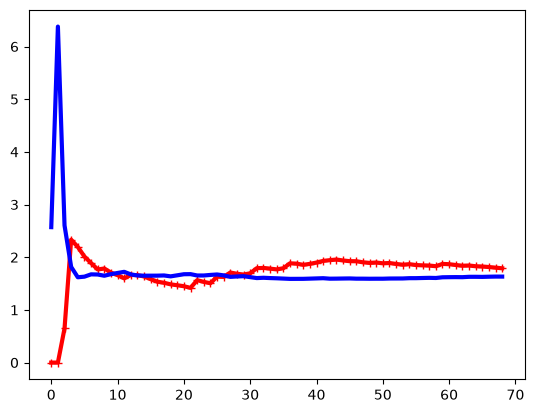

In [44]:
lin_reg = LinearRegression()
plot_learning_curves(lin_reg, X, y)

/tmp/ipykernel_63249/287259343.py:70: UserWarning: The `rotation` parameter has not yet been implemented and is currently ignored.
  ax.text(-0.5, -2.9, -0.3, "Parameters x, y", color="#666", fontsize=12, rotation=-20)
/tmp/ipykernel_63249/287259343.py:71: UserWarning: The `rotation` parameter has not yet been implemented and is currently ignored.
  ax.text(2.4, 1.2, -0.3, "Loss Z", color="#666", fontsize=12, rotation=38)


Hoàn thành! Đã lưu file: gradient_descent_znoy_pulsing_glow.gif


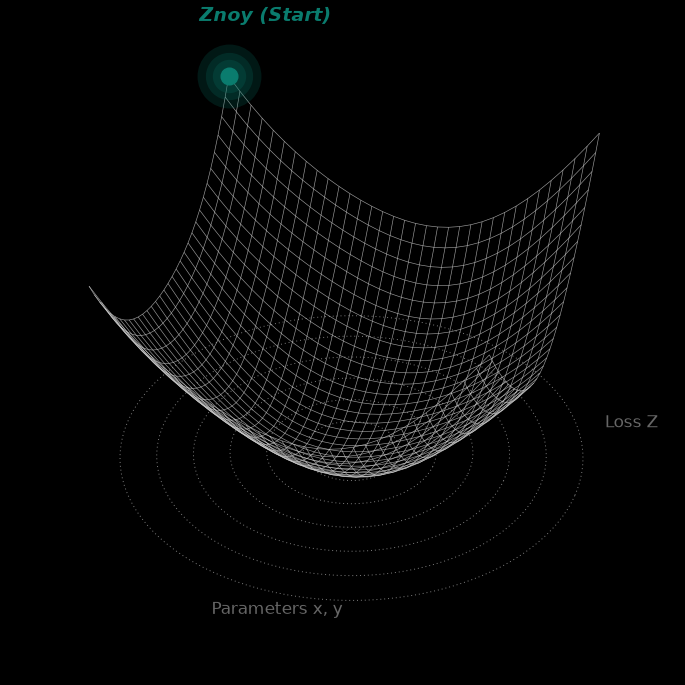

Đang vẽ từng khung hình... (Có thể mất 15-20 giây)
Tuyệt vời! Đã xuất xong file: gradient_descent_znoy_tracing.gif


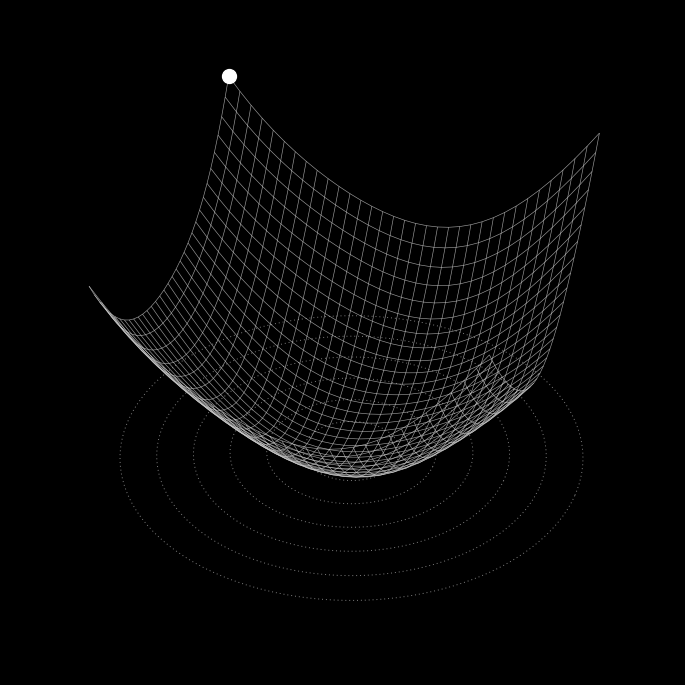

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

fig = plt.figure(figsize=(7, 7), facecolor="black")
ax = fig.add_axes([0, 0, 1, 0.95], projection="3d", facecolor="black")
ax.set_axis_off()

# ==========================================
# 1. Vẽ bề mặt Loss và các vòng Contour
# ==========================================
n = 34
g = np.linspace(-2, 2, n)
X, Y = np.meshgrid(g, g)
Z = X**2 + Y**2 + 0.25*np.sin(2*X)*np.cos(2*Y)
ax.plot_wireframe(X, Y, Z, rstride=1, cstride=1, color="#d0d0d0", lw=0.45, alpha=0.75)

th = np.linspace(0, 2*np.pi, 300)
for r in np.linspace(0.5, 2.4, 6):
    ax.plot(r*np.cos(th), r*np.sin(th), 0*th - 0.3, color="white", lw=0.7, ls=(0, (1, 3)), alpha=0.5)

# ==========================================
# 2. Tính toán đường đi Gradient Descent (Chưa vẽ ngay)
# ==========================================
p = np.array([-2.0, 2.0]); lr = 0.09; path = [p.copy()]
for _ in range(28):
    p = p - lr*2*p
    path.append(p.copy())
path = np.array(path)
pz = (path**2).sum(1) + 0.25*np.sin(2*path[:, 0])*np.cos(2*path[:, 1])
path_x, path_y, path_z = path[:, 0], path[:, 1], pz

TOTAL_STEPS = len(path_x) # Khoảng 29 bước

# ==========================================
# 3. Khởi tạo các đối tượng Animation (Ban đầu ẩn đi)
# ==========================================
# 3.1 Đường nét đứt (Path)
line, = ax.plot([], [], [], color='white', linestyle='--', linewidth=2.5,
                marker='', markersize=6, markerfacecolor='white', markeredgecolor='#0d1117', zorder=5)

# 3.2 Điểm sáng chạy ở đầu đường (Tracer Head)
head_dot, = ax.plot([], [], [], marker='o', color='white', markersize=10, zorder=6)

# 3.3 Hiệu ứng Glow và Cực tiểu (Chỉ hiện khi đến đích)
MIN_COLOR = "#0A7C6E"
glows = []
for ms, al in [(46, .10), (34, .14), (24, .22)]:
    g, = ax.plot([], [], [], marker='o', color=MIN_COLOR, markersize=ms, alpha=al, markeredgewidth=0, zorder=5)
    glows.append(g)

# 3.4 Text Znoy
txt_znoy = ax.text(0.45, 0, -0.2, "", color="white", fontsize=15, fontweight='bold', style="italic")
txt_min = ax.text(0.45, 0, -0.8, "", color="#8b949e", fontsize=11, style="italic")

# Nhãn đồ thị tĩnh
x
ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_zlim(-0.4, 8)
ax.set_box_aspect((1, 1, 0.7))

# ==========================================
# 4. Hàm Cập nhật Khung hình (Animation Update)
# ==========================================
TOTAL_FRAMES = 60 # Tổng cộng 60 khung hình cho 1 chu kỳ GIF

def update_tracing(frame):
    # 1. Camera lướt qua lại mượt mà để tạo loop hoàn hảo
    azim = -72 + 15 * np.sin(np.pi * 2 * frame / TOTAL_FRAMES)
    ax.view_init(elev=36, azim=azim)
    
    # 2. Xử lý đường chạy
    # Vẽ lần lượt từng đoạn đến khi chạm mốc TOTAL_STEPS
    idx = min(frame, TOTAL_STEPS - 1)
    
    line.set_data(path_x[:idx+1], path_y[:idx+1])
    line.set_3d_properties(path_z[:idx+1])
    
    # Dấu chấm to chạy ở đầu
    head_dot.set_data([path_x[idx]], [path_y[idx]])
    head_dot.set_3d_properties([path_z[idx]])
    
    # 3. Kích hoạt vụ nổ ánh sáng và Text Znoy khi chạy đến đích
    if frame >= TOTAL_STEPS - 1:
        for g in glows:
            g.set_data([0], [0])
            g.set_3d_properties([0])
        
        txt_min.set_text("(Local Minimum)")
    else:
        # Nếu chưa đến đích thì ẩn đi
        for g in glows:
            g.set_data([], [])
            g.set_3d_properties([])
        
        txt_znoy.set_text("")
        txt_min.set_text("")

    return fig,

# ==========================================
# 5. Xuất file GIF
# ==========================================
ani = FuncAnimation(fig, update_tracing, frames=TOTAL_FRAMES, interval=50, blit=False)

print("Đang vẽ từng khung hình... (Có thể mất 15-20 giây)")
ani.save("gradient_descent_znoy_tracing.gif", writer=PillowWriter(fps=15))
print("Tuyệt vời! Đã xuất xong file: gradient_descent_znoy_tracing.gif")